# Offline binary KNN: attack vs. benign

Trains and evaluates a K-Nearest-Neighbors classifier on first-N-packet flow features.

| Class | Source | File |
|---|---|---|
| Attack (1) | CICDDoS2019 03-11, labeled by CSV join | `preprocessing/features_out/attack_features_n{N}.csv` |
| Benign (0) | MAWI DITL 2026-04-08 | `preprocessing/features_out/benign_features_n{N}.csv` |

Pipeline: **load → inspect → clean → join → balance → split → select features → train → test → compare** across
`N` (packets per flow), feature set, and `k`.

> **Known dataset artifact.** The MAWI pcap was captured with `snaplen=96` and the extractors record
> `len(buf)` (captured bytes), so benign `packet_length_*`, `total_bytes` and `bytes_per_second` are capped
> at 96 bytes, while attack packets go up to 1514. Any feature set that includes these columns can separate
> the classes on that artifact alone. The `no_size` feature set below excludes them. The real fix is to
> re-extract using the IP total-length field (`ip.len`) instead of `len(buf)`.

## 1. Configuration

In [43]:
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, precision_score,
    recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

PROJECT_DIR = Path("/home/ubuntu/DDoS_ML")
FEATURES_DIR = PROJECT_DIR / "preprocessing" / "features_out"
MODELS_DIR = PROJECT_DIR / "offline" / "models"
RESULTS_DIR = PROJECT_DIR / "offline" / "results"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

N_VALUES = [3, 4, 5]                 # packets per flow; one attack/benign CSV pair per N
K_VALUES = [1, 3, 5, 7, 9, 11, 15]   # odd values only: no voting ties in binary KNN

# Attack-file labels that are not attacks. CICDDoS2019 "BENIGN" rows are dropped so that the
# benign class comes from a single source (MAWI); "unknown" rows had no CSV label match.
ATTACK_DROP_LABELS = {"BENIGN", "unknown"}

DROP_DUPLICATES = True       # drop exact duplicate feature vectors per class (avoids train/test leakage)
SAMPLES_PER_CLASS = 500_000  # balanced sample per class after cleaning (None = use all, very slow for KNN)
TEST_SIZE = 0.3
RANDOM_STATE = 42

# Feature preprocessing for training/testing (Sections 7 and 9):
#   "raw"    - features as extracted from the PCAPs, no preprocessing
#   "scaled" - StandardScaler fit on the training split only, applied to train and test
FEATURE_SCALING = "raw"
assert FEATURE_SCALING in ("raw", "scaled"), f"FEATURE_SCALING must be 'raw' or 'scaled', got {FEATURE_SCALING!r}"

### Candidate features and identifier columns

These are the **candidate** features: everything the analysis in Section 6 looks at. The features actually
used for training and testing are chosen **after** that analysis, in the Section 6 cell
"Selected features for training".

The 5-tuple (`src_ip`, `dst_ip`, `src_port`, `dst_port`, `protocol`) is loaded and kept in every dataframe
so each row can be traced back to its flow, but it is **never a candidate feature**, and an assertion below
enforces that. Timestamps are not loaded. `packet_count` is loaded only to check that it equals N.

`proto_tcp` / `proto_udp` / `proto_other` are one-hot flags derived from `protocol` (the transport type,
not the flow identity). Zero-variance columns (e.g. `tcp_urg_count`) are removed after cleaning.

In [2]:
SIZE_FEATURES = [
    "total_bytes", "bytes_per_second",
    "packet_length_min", "packet_length_max", "packet_length_mean", "packet_length_std",
]
TIMING_FEATURES = [
    "duration", "packets_per_second",
    "iat_min", "iat_max", "iat_mean", "iat_std",
]
FLAG_FEATURES = [
    "tcp_syn_count", "tcp_ack_count", "tcp_fin_count",
    "tcp_rst_count", "tcp_psh_count", "tcp_urg_count",
]
PROTO_FEATURES = ["proto_tcp", "proto_udp", "proto_other"]

CANDIDATE_FEATURES = TIMING_FEATURES + SIZE_FEATURES + FLAG_FEATURES + PROTO_FEATURES

# 5-tuple identifiers: kept in the dataframes for traceability, never used as features.
ID_COLUMNS = ["src_ip", "dst_ip", "src_port", "dst_port", "protocol"]

leaked = set(CANDIDATE_FEATURES) & set(ID_COLUMNS)
assert not leaked, f"Candidate features contain identifier columns: {leaked}"

## 2. Load the CSV files

In [3]:
RAW_FEATURE_COLUMNS = [c for c in CANDIDATE_FEATURES if c not in PROTO_FEATURES]
LOAD_COLUMNS = ID_COLUMNS + ["packet_count"] + RAW_FEATURE_COLUMNS + ["label"]
PROTO_NAME_TO_NUM = {"TCP": 6, "UDP": 17}


def load_features(path):
    df = pd.read_csv(
        path, usecols=LOAD_COLUMNS,
        dtype={"src_ip": str, "dst_ip": str, "protocol": str, "label": str},
    )
    df = df[LOAD_COLUMNS]  # usecols keeps file order; force the same column order for both files
    # The attack extractor writes protocol numbers ("6"/"17"), the benign one writes names ("TCP"/"UDP").
    proto = pd.to_numeric(df["protocol"].map(lambda p: PROTO_NAME_TO_NUM.get(p, p)), errors="coerce")
    df["protocol"] = proto.astype("Int16")
    df["proto_tcp"] = (proto == 6).astype(np.int8)
    df["proto_udp"] = (proto == 17).astype(np.int8)
    df["proto_other"] = (~proto.isin([6, 17])).astype(np.int8)
    return df


def load_n(n):
    attack = load_features(FEATURES_DIR / f"attack_features_n{n}.csv")
    benign = load_features(FEATURES_DIR / f"benign_features_n{n}.csv")

    # Nothing is dropped here: BENIGN/unknown attack-file rows are removed in the cleaning step,
    # so the inspection section shows exactly what was in the CSVs.
    attack["attack_type"] = attack.pop("label")
    attack["y"] = 1
    benign["attack_type"] = "Benign"
    benign.pop("label")
    benign["y"] = 0
    return attack, benign


raw = {}
for n in N_VALUES:
    t0 = time.time()
    raw[n] = load_n(n)
    a, b = raw[n]
    print(f"N={n}: attack={len(a):>10,}  benign={len(b):>10,}  ({time.time() - t0:.0f}s)")

N=3: attack= 2,769,585  benign= 2,476,811  (16s)
N=4: attack= 2,769,443  benign= 2,081,499  (14s)
N=5: attack= 1,368,876  benign= 1,820,701  (9s)


## 3. Inspect the loaded data

Checks run **before** any cleaning, on the full loaded dataframes:

1. Raw CSV headers: which columns each file has, and which were not loaded.
2. Shapes and a preview of each dataframe.
3. Schema: attack and benign have identical columns and dtypes; every feature is numeric.
4. Column roles: identifier / feature / label / check-only, and which feature sets use each feature.
5. Missing and infinite values.
6. `packet_count` equals N in every row.
7. Protocol and label distributions.
8. Per-class feature ranges, flagging features whose attack and benign ranges do not overlap.
9. Constant columns.
10. Duplicate feature vectors and 5-tuple statistics, including IPs that appear in both classes.

In [4]:
from IPython.display import display

# 1. Raw CSV headers (read without loading data).
for n in N_VALUES:
    a_cols = pd.read_csv(FEATURES_DIR / f"attack_features_n{n}.csv", nrows=0).columns.tolist()
    b_cols = pd.read_csv(FEATURES_DIR / f"benign_features_n{n}.csv", nrows=0).columns.tolist()
    common = [c for c in a_cols if c in b_cols]
    print(f"N={n}: attack CSV has {len(a_cols)} columns, benign CSV has {len(b_cols)}, common {len(common)}")
    print("  only in attack :", [c for c in a_cols if c not in b_cols])
    print("  only in benign :", [c for c in b_cols if c not in a_cols])
    print("  common, not loaded:", [c for c in common if c not in LOAD_COLUMNS])
    missing = [c for c in LOAD_COLUMNS if c not in common]
    assert not missing, f"Columns required by LOAD_COLUMNS missing from a CSV: {missing}"

N=3: attack CSV has 29 columns, benign CSV has 25, common 25
  only in attack : ['flow_start_time', 'flow_end_time', 'label_source', 'csv_match_time_diff']
  only in benign : []
  common, not loaded: []
N=4: attack CSV has 29 columns, benign CSV has 25, common 25
  only in attack : ['flow_start_time', 'flow_end_time', 'label_source', 'csv_match_time_diff']
  only in benign : []
  common, not loaded: []
N=5: attack CSV has 29 columns, benign CSV has 25, common 25
  only in attack : ['flow_start_time', 'flow_end_time', 'label_source', 'csv_match_time_diff']
  only in benign : []
  common, not loaded: []


In [5]:
# 2. Shapes and preview.
for n in N_VALUES:
    a, b = raw[n]
    mem = (a.memory_usage(deep=True).sum() + b.memory_usage(deep=True).sum()) / 1e9
    print(f"===== N={n}: attack {a.shape}, benign {b.shape}, memory {mem:.2f} GB")
    display(a.head(3))
    display(b.head(3))

===== N=3: attack (2769585, 29), benign (2476811, 29), memory 2.02 GB


,src_ip,dst_ip,src_port,dst_port,protocol,packet_count,duration,packets_per_second,iat_min,iat_max,iat_mean,iat_std,total_bytes,bytes_per_second,packet_length_min,packet_length_max,packet_length_mean,packet_length_std,tcp_syn_count,tcp_ack_count,tcp_fin_count,tcp_rst_count,tcp_psh_count,tcp_urg_count,proto_tcp,proto_udp,proto_other,attack_type,y
0,172.16.0.5,192.168.50.4,0,0,17,3,0.000047,63872.649746,9.536743e-07,0.000046,0.000023,0.000032,4542,9.670319e+07,1514,1514,1514.0,0.0,0,0,0,0,0,0,0,1,0,unknown,1
1,172.16.0.5,192.168.50.4,15980,31526,17,3,0.000497,6034.969784,9.536743e-07,0.000496,0.000249,0.000350,1395,2.806261e+06,465,465,465.0,0.0,0,0,0,0,0,0,0,1,0,MSSQL,1
2,172.16.0.5,192.168.50.4,61850,50412,17,3,0.000517,5801.250346,0.000000e+00,0.000517,0.000259,0.000366,1395,2.697581e+06,465,465,465.0,0.0,0,0,0,0,0,0,0,1,0,MSSQL,1


,src_ip,dst_ip,src_port,dst_port,protocol,packet_count,duration,packets_per_second,iat_min,iat_max,iat_mean,iat_std,total_bytes,bytes_per_second,packet_length_min,packet_length_max,packet_length_mean,packet_length_std,tcp_syn_count,tcp_ack_count,tcp_fin_count,tcp_rst_count,tcp_psh_count,tcp_urg_count,proto_tcp,proto_udp,proto_other,attack_type,y
0,157.209.43.67,47.173.135.177,80,48978,6,3,0.000066,45425.675090,0.000031,0.000035,0.000033,0.000003,198,2.998095e+06,66,66,66.0,0.0,0,3,0,0,0,0,1,0,0,Benign,0
1,146.195.151.206,150.189.32.126,443,32840,6,3,0.000031,96791.630769,0.000009,0.000022,0.000015,0.000009,198,6.388248e+06,66,66,66.0,0.0,0,3,0,0,1,0,1,0,0,Benign,0
2,2001:4dfb:ea23:2c79:2d7c:7441:5e5c:1033,2404:643b:cb88:300e:7eff:8b8c:27f0:7f41,57765,443,17,3,0.000078,38479.853211,0.000002,0.000076,0.000039,0.000052,186,2.385751e+06,62,62,62.0,0.0,0,0,0,0,0,0,0,1,0,Benign,0


===== N=4: attack (2769443, 29), benign (2081499, 29), memory 1.86 GB


,src_ip,dst_ip,src_port,dst_port,protocol,packet_count,duration,packets_per_second,iat_min,iat_max,iat_mean,iat_std,total_bytes,bytes_per_second,packet_length_min,packet_length_max,packet_length_mean,packet_length_std,tcp_syn_count,tcp_ack_count,tcp_fin_count,tcp_rst_count,tcp_psh_count,tcp_urg_count,proto_tcp,proto_udp,proto_other,attack_type,y
0,172.16.0.5,192.168.50.4,0,0,17,4,0.000048,83468.736318,9.536743e-07,0.000046,0.000016,0.000026,5131,1.070695e+08,589,1514,1282.75,462.5,0,0,0,0,0,0,0,1,0,unknown,1
1,172.16.0.5,192.168.50.4,15980,31526,17,4,0.000498,8031.218765,9.536743e-07,0.000496,0.000166,0.000286,1860,3.734517e+06,465,465,465.00,0.0,0,0,0,0,0,0,0,1,0,MSSQL,1
2,172.16.0.5,192.168.50.4,61850,50412,17,4,0.000518,7720.762080,0.000000e+00,0.000517,0.000173,0.000298,1860,3.590154e+06,465,465,465.00,0.0,0,0,0,0,0,0,0,1,0,MSSQL,1


,src_ip,dst_ip,src_port,dst_port,protocol,packet_count,duration,packets_per_second,iat_min,iat_max,iat_mean,iat_std,total_bytes,bytes_per_second,packet_length_min,packet_length_max,packet_length_mean,packet_length_std,tcp_syn_count,tcp_ack_count,tcp_fin_count,tcp_rst_count,tcp_psh_count,tcp_urg_count,proto_tcp,proto_udp,proto_other,attack_type,y
0,157.209.43.67,47.173.135.177,80,48978,6,4,0.000075,53261.003175,0.000009,0.000035,0.000025,0.000014,264,3.515226e+06,66,66,66.0,0.0,0,4,0,0,0,0,1,0,0,Benign,0
1,2001:4dfb:ea23:2c79:2d7c:7441:5e5c:1033,2404:643b:cb88:300e:7eff:8b8c:27f0:7f41,57765,443,17,4,0.000080,50081.241791,0.000002,0.000076,0.000027,0.000043,248,3.105037e+06,62,62,62.0,0.0,0,0,0,0,0,0,0,1,0,Benign,0
2,71.81.13.209,150.189.109.193,443,58208,6,4,0.000017,233016.888889,0.000004,0.000007,0.000006,0.000002,264,1.537911e+07,66,66,66.0,0.0,0,4,0,0,0,0,1,0,0,Benign,0


===== N=5: attack (1368876, 29), benign (1820701, 29), memory 1.23 GB


,src_ip,dst_ip,src_port,dst_port,protocol,packet_count,duration,packets_per_second,iat_min,iat_max,iat_mean,iat_std,total_bytes,bytes_per_second,packet_length_min,packet_length_max,packet_length_mean,packet_length_std,tcp_syn_count,tcp_ack_count,tcp_fin_count,tcp_rst_count,tcp_psh_count,tcp_urg_count,proto_tcp,proto_udp,proto_other,attack_type,y
0,172.16.0.5,192.168.50.4,0,0,17,5,0.000049,101803.495146,9.536743e-07,0.000046,0.000012,0.000022,6645,1.352968e+08,589,1514,1329.0,413.672576,0,0,0,0,0,0,0,1,0,unknown,1
1,192.168.50.4,172.16.0.5,0,0,1,5,0.815146,6.133871,9.536743e-07,0.479559,0.203786,0.242541,1392,1.707670e+03,70,590,278.4,284.451753,0,0,0,0,0,0,0,0,1,unknown,1
2,192.168.50.9,172.217.3.99,53776,443,6,5,0.000130,38479.853211,0.000000e+00,0.000128,0.000032,0.000064,484,3.724850e+06,66,112,96.8,18.780309,0,5,1,0,4,0,1,0,0,BENIGN,1


,src_ip,dst_ip,src_port,dst_port,protocol,packet_count,duration,packets_per_second,iat_min,iat_max,iat_mean,iat_std,total_bytes,bytes_per_second,packet_length_min,packet_length_max,packet_length_mean,packet_length_std,tcp_syn_count,tcp_ack_count,tcp_fin_count,tcp_rst_count,tcp_psh_count,tcp_urg_count,proto_tcp,proto_udp,proto_other,attack_type,y
0,157.209.43.67,47.173.135.177,80,48978,6,5,0.000128,39053.109870,9.059906e-06,0.000053,0.000032,0.000018,330,2.577505e+06,66,66,66.0,0.0,0,5,0,0,0,0,1,0,0,Benign,0
1,71.81.13.209,150.189.109.193,443,58208,6,5,0.000023,216201.237113,3.814697e-06,0.000007,0.000006,0.000001,330,1.426928e+07,66,66,66.0,0.0,0,5,0,0,0,0,1,0,0,Benign,0
2,150.189.111.84,162.103.113.232,61885,443,17,5,0.000230,21754.688797,9.536743e-07,0.000129,0.000057,0.000065,210,9.136969e+05,42,42,42.0,0.0,0,0,0,0,0,0,0,1,0,Benign,0


In [6]:
# 3. Schema: identical columns and dtypes between attack and benign; features numeric.
for n in N_VALUES:
    a, b = raw[n]
    assert list(a.columns) == list(b.columns), (
        f"N={n}: column mismatch\n attack only: {set(a.columns) - set(b.columns)}\n"
        f" benign only: {set(b.columns) - set(a.columns)}"
    )
    dtypes = pd.DataFrame({"attack": a.dtypes.astype(str), "benign": b.dtypes.astype(str)})
    mismatched = dtypes[dtypes["attack"] != dtypes["benign"]]
    non_numeric = [c for c in CANDIDATE_FEATURES
                   if not (pd.api.types.is_numeric_dtype(a[c]) and pd.api.types.is_numeric_dtype(b[c]))]
    print(f"N={n}: {len(a.columns)} identical columns, dtype mismatches={len(mismatched)}, "
          f"non-numeric features={non_numeric}")
    if len(mismatched):
        display(mismatched)
    assert not non_numeric, f"N={n}: non-numeric feature columns {non_numeric}"

dtypes

N=3: 29 identical columns, dtype mismatches=0, non-numeric features=[]
N=4: 29 identical columns, dtype mismatches=0, non-numeric features=[]
N=5: 29 identical columns, dtype mismatches=0, non-numeric features=[]


,attack,benign
src_ip,object,object
dst_ip,object,object
src_port,int64,int64
dst_port,int64,int64
protocol,Int16,Int16
packet_count,int64,int64
duration,float64,float64
packets_per_second,float64,float64
iat_min,float64,float64
iat_max,float64,float64


In [7]:
# 4. Column roles. Only candidate features can be selected for training (Section 6).
def column_role(col):
    if col in ID_COLUMNS:
        return "identifier (5-tuple, not a feature)"
    if col in ("attack_type", "y"):
        return "label"
    if col == "packet_count":
        return "check only (must equal N)"
    if col in CANDIDATE_FEATURES:
        return "candidate feature"
    return "other"


roles = pd.DataFrame({"column": raw[N_VALUES[0]][0].columns})
roles["role"] = roles["column"].map(column_role)
roles

,column,role
0,src_ip,"identifier (5-tuple, not a feature)"
1,dst_ip,"identifier (5-tuple, not a feature)"
2,src_port,"identifier (5-tuple, not a feature)"
3,dst_port,"identifier (5-tuple, not a feature)"
4,protocol,"identifier (5-tuple, not a feature)"
5,packet_count,check only (must equal N)
6,duration,candidate feature
7,packets_per_second,candidate feature
8,iat_min,candidate feature
9,iat_max,candidate feature


In [8]:
# 5. Missing and infinite values (only columns with at least one bad value are listed).
for n in N_VALUES:
    rows = []
    for cls, df in zip(["attack", "benign"], raw[n]):
        numeric = df.select_dtypes(include="number")
        for col in df.columns:
            n_nan = int(df[col].isna().sum())
            n_inf = int(np.isinf(numeric[col]).sum()) if col in numeric else 0
            if n_nan or n_inf:
                rows.append({"class": cls, "column": col, "nan": n_nan, "inf": n_inf})
    print(f"N={n}: {'no NaN/inf values' if not rows else f'{len(rows)} column(s) with NaN/inf'}")
    if rows:
        display(pd.DataFrame(rows))

N=3: no NaN/inf values
N=4: no NaN/inf values
N=5: no NaN/inf values


In [9]:
# 6. packet_count must equal N (flows are only written once they reach N packets).
for n in N_VALUES:
    a, b = raw[n]
    bad_a, bad_b = int((a["packet_count"] != n).sum()), int((b["packet_count"] != n).sum())
    print(f"N={n}: rows with packet_count != {n}: attack={bad_a:,}  benign={bad_b:,}")

N=3: rows with packet_count != 3: attack=0  benign=0
N=4: rows with packet_count != 4: attack=0  benign=0
N=5: rows with packet_count != 5: attack=0  benign=0


In [10]:
# 7a. Protocol distribution per class (% of rows).
PROTO_NAMES = {1: "ICMP", 6: "TCP", 17: "UDP", 58: "ICMPv6"}
proto_tables = {}
for n in N_VALUES:
    for cls, df in zip(["attack", "benign"], raw[n]):
        counts = df["protocol"].map(lambda p: PROTO_NAMES.get(p, f"other ({p})")).value_counts(normalize=True)
        proto_tables[(f"N={n}", cls)] = (counts * 100).round(2)
pd.DataFrame(proto_tables).fillna(0)

N=3           N=4           N=5       
            attack benign attack benign attack benign
protocol                                             
ICMP          0.01   9.37   0.01   9.26   0.02   9.72
ICMPv6        0.01   5.26   0.01   3.44   0.01   2.61
TCP          28.80  78.54  28.80  80.05  45.18  79.89
UDP          71.17   6.82  71.18   7.26  54.78   7.78
other (103)   0.00   0.00   0.00   0.00   0.00   0.00
other (2)     0.00   0.00   0.00   0.00   0.00   0.00
other (41)    0.00   0.00   0.00   0.00   0.00   0.00
other (47)    0.00   0.00   0.00   0.00   0.00   0.00
other (50)    0.00   0.00   0.00   0.00   0.00   0.00
other (89)    0.01   0.00   0.01   0.00   0.01   0.00
other (9)     0.00   0.00   0.00   0.00   0.00   0.00
other (97)    0.00   0.00   0.00   0.00   0.00   0.00

In [11]:
# 7b. Label distribution per N. Labels in ATTACK_DROP_LABELS are removed in the cleaning step.
labels = pd.DataFrame({
    f"N={n}": pd.concat([raw[n][0]["attack_type"], raw[n][1]["attack_type"]]).value_counts()
    for n in N_VALUES
}).fillna(0).astype(int)
labels["dropped_in_cleaning"] = labels.index.isin(ATTACK_DROP_LABELS).astype(str)
labels

,N=3,N=4,N=5,dropped_in_cleaning
attack_type,,,,
BENIGN,23744,23722,20794,True
Benign,2476811,2081499,1820701,False
LDAP,2286,2286,472,False
MSSQL,19417,19417,272,False
NetBIOS,6628,6628,1484,False
Portmap,363,363,168,False
Syn,754745,754745,590817,False
UDP,1941505,1941499,746672,False
UDPLag,150,150,101,False


In [12]:
# 8. Per-class feature ranges. "overlap" = False means a single threshold on that feature separates
#    the classes perfectly. Also compare benign_max of the size features: it never exceeds 96 bytes
#    (MAWI snaplen), while attack packets reach 1514+.
for n in N_VALUES:
    a, b = raw[n]
    feats = [c for c in CANDIDATE_FEATURES if c not in PROTO_FEATURES]
    summary = pd.DataFrame({
        "attack_min": a[feats].min(), "attack_median": a[feats].median(), "attack_max": a[feats].max(),
        "benign_min": b[feats].min(), "benign_median": b[feats].median(), "benign_max": b[feats].max(),
    })
    summary["overlap"] = (summary["attack_min"] <= summary["benign_max"]) & \
                         (summary["benign_min"] <= summary["attack_max"])
    print(f"===== N={n}  features with NO overlap between classes: "
          f"{summary.index[~summary['overlap']].tolist()}")
    display(summary.map(lambda v: float(f"{v:.6g}") if isinstance(v, float) else v))

===== N=3  features with NO overlap between classes: []


,attack_min,attack_median,attack_max,benign_min,benign_median,benign_max,overlap
duration,0.0,1.081500e-01,3.600410e+03,9.536740e-07,1.999910,2.406410e+02,True
packets_per_second,0.0,2.773920e+01,3.145730e+06,1.246670e-02,1.500070,3.145730e+06,True
iat_min,0.0,9.536740e-07,4.538400e+01,0.000000e+00,0.293130,1.203210e+02,True
iat_max,0.0,1.081390e-01,3.600410e+03,9.536740e-07,1.006100,1.204600e+02,True
iat_mean,0.0,5.407500e-02,1.800200e+03,4.768370e-07,0.999955,1.203210e+02,True
iat_std,0.0,7.645940e-02,2.545870e+03,0.000000e+00,0.196004,8.503170e+01,True
total_bytes,180.0,1.098000e+03,8.011000e+03,1.020000e+02,198.000000,2.880000e+02,True
bytes_per_second,0.0,1.057190e+04,2.153780e+09,5.236850e-01,116.449000,2.705330e+08,True
packet_length_min,60.0,3.630000e+02,1.827000e+03,3.400000e+01,66.000000,9.600000e+01,True
packet_length_max,60.0,3.720000e+02,3.523000e+03,3.400000e+01,70.000000,9.600000e+01,True


===== N=4  features with NO overlap between classes: []


,attack_min,attack_median,attack_max,benign_min,benign_median,benign_max,overlap
duration,9.536740e-07,1.081540e-01,3.600410e+03,1.907350e-06,1.528430,3.609270e+02,True
packets_per_second,1.110980e-03,3.698430e+01,4.194300e+06,1.108260e-02,2.617060,2.097150e+06,True
iat_min,0.000000e+00,9.536740e-07,4.500040e+01,0.000000e+00,0.031937,1.202920e+02,True
iat_max,9.536740e-07,1.081400e-01,3.600410e+03,9.536740e-07,1.004110,1.204420e+02,True
iat_mean,3.178910e-07,3.605140e-02,1.200140e+03,6.357830e-07,0.509477,1.203090e+02,True
iat_std,0.000000e+00,6.243110e-02,2.078700e+03,0.000000e+00,0.259480,6.942810e+01,True
total_bytes,2.400000e+02,1.470000e+03,1.007400e+04,1.360000e+02,264.000000,3.840000e+02,True
bytes_per_second,8.887880e-02,1.419600e+04,2.642410e+09,4.654680e-01,156.674000,1.300230e+08,True
packet_length_min,6.000000e+01,3.630000e+02,1.827000e+03,3.400000e+01,66.000000,9.600000e+01,True
packet_length_max,6.000000e+01,3.720000e+02,3.523000e+03,3.400000e+01,74.000000,9.600000e+01,True


===== N=5  features with NO overlap between classes: []


,attack_min,attack_median,attack_max,benign_min,benign_median,benign_max,overlap
duration,9.536740e-07,2.188020e-01,3.600100e+03,2.861020e-06,1.689790,4.811570e+02,True
packets_per_second,1.388850e-03,2.285170e+01,5.242880e+06,1.039160e-02,2.958940,1.747630e+06,True
iat_min,0.000000e+00,9.536740e-07,4.499990e+01,0.000000e+00,0.002125,1.202790e+02,True
iat_max,9.536740e-07,1.105820e-01,3.600100e+03,9.536740e-07,0.847846,1.204080e+02,True
iat_mean,2.384190e-07,5.470050e-02,9.000250e+02,7.152560e-07,0.422448,1.202890e+02,True
iat_std,0.000000e+00,6.316190e-02,1.800050e+03,0.000000e+00,0.172677,6.936700e+01,True
total_bytes,3.000000e+02,1.905000e+03,1.049000e+04,1.700000e+02,330.000000,4.800000e+02,True
bytes_per_second,1.349270e-01,8.708880e+03,2.500850e+09,4.364480e-01,185.882000,1.083530e+08,True
packet_length_min,6.000000e+01,3.630000e+02,1.514000e+03,3.400000e+01,66.000000,9.600000e+01,True
packet_length_max,6.000000e+01,4.350000e+02,3.523000e+03,3.400000e+01,74.000000,9.600000e+01,True


In [13]:
# 9. Constant columns per class (a single unique value).
for n in N_VALUES:
    for cls, df in zip(["attack", "benign"], raw[n]):
        const = [c for c in CANDIDATE_FEATURES if df[c].nunique(dropna=False) <= 1]
        print(f"N={n} {cls:<6}: constant features {const}")

N=3 attack: constant features ['tcp_urg_count']
N=3 benign: constant features ['tcp_urg_count']
N=4 attack: constant features ['tcp_urg_count']
N=4 benign: constant features ['tcp_urg_count']
N=5 attack: constant features ['tcp_urg_count']
N=5 benign: constant features ['tcp_urg_count']


In [14]:
# 10. Duplicates and 5-tuple statistics.
rows = []
for n in N_VALUES:
    a, b = raw[n]
    ips_a = set(a["src_ip"]) | set(a["dst_ip"])
    ips_b = set(b["src_ip"]) | set(b["dst_ip"])
    shared_ips = len(ips_a & ips_b)
    for cls, df in zip(["attack", "benign"], raw[n]):
        dup_feat = int(df.duplicated(subset=CANDIDATE_FEATURES).sum())
        dup_5t = int(df.duplicated(subset=ID_COLUMNS).sum())
        rows.append({
            "N": n, "class": cls, "rows": len(df),
            "duplicate_feature_vectors": dup_feat, "duplicate_feature_pct": 100 * dup_feat / len(df),
            "unique_5tuples": len(df) - dup_5t,
            "repeated_5tuple_rows": dup_5t,  # same 5-tuple written again after the flow timeout
            "unique_src_ip": df["src_ip"].nunique(), "unique_dst_ip": df["dst_ip"].nunique(),
            "ips_shared_with_other_class": shared_ips,
        })
pd.DataFrame(rows).round(2)

,N,class,rows,duplicate_feature_vectors,duplicate_feature_pct,unique_5tuples,repeated_5tuple_rows,unique_src_ip,unique_dst_ip,ips_shared_with_other_class
0,3,attack,2769585,1479181,53.41,2163660,605925,1275,1285,2
1,3,benign,2476811,44385,1.79,2357569,119242,235325,200333,2
2,4,attack,2769443,1254447,45.30,2163655,605788,1275,1285,2
3,4,benign,2081499,8970,0.43,2002752,78747,202335,143267,2
4,5,attack,1368876,8038,0.59,892876,476000,1272,1284,2
5,5,benign,1820701,2937,0.16,1762733,57968,179528,119095,2


## 4. Clean, deduplicate, and join

* Drop attack-file rows whose label is in `ATTACK_DROP_LABELS` (`BENIGN`, `unknown`).
* Replace `inf` with NaN and drop rows with NaN in any feature.
* Drop exact duplicate feature vectors within each class (flood traffic produces many identical vectors;
  leaving them in lets KNN "find itself" in the training set). The 5-tuple is not part of the comparison,
  so two flows with different 5-tuples but identical features count as duplicates.
* Report feature vectors that appear in **both** classes; no classifier can separate those.
* Draw a balanced sample of `SAMPLES_PER_CLASS` per class and join into one frame. The 5-tuple columns
  are carried along for traceability.

In [15]:
def clean(df, name):
    before = len(df)
    df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=CANDIDATE_FEATURES)
    after_na = len(df)
    if DROP_DUPLICATES:
        df = df.drop_duplicates(subset=CANDIDATE_FEATURES)
    print(f"  {name:<7} rows={before:>10,}  after_nan={after_na:>10,}  after_dedup={len(df):>10,}")
    return df


data = {}
clean_stats = []
for n in N_VALUES:
    print(f"N={n}")
    attack, benign = raw[n]
    dropped = attack["attack_type"].isin(ATTACK_DROP_LABELS)
    print(f"  dropped attack rows labeled {sorted(ATTACK_DROP_LABELS)}: {int(dropped.sum()):,}")
    attack = attack[~dropped]
    attack = clean(attack, "attack")
    benign = clean(benign, "benign")

    overlap = attack[CANDIDATE_FEATURES].merge(benign[CANDIDATE_FEATURES].drop_duplicates(), how="inner")
    print(f"  feature vectors present in both classes: {len(overlap):,}")

    n_per_class = min(len(attack), len(benign))
    if SAMPLES_PER_CLASS is not None:
        n_per_class = min(n_per_class, SAMPLES_PER_CLASS)
    attack_s = attack.sample(n=n_per_class, random_state=RANDOM_STATE)
    benign_s = benign.sample(n=n_per_class, random_state=RANDOM_STATE)

    data[n] = pd.concat([attack_s, benign_s], ignore_index=True)
    clean_stats.append({
        "N": n, "attack_clean": len(attack), "benign_clean": len(benign),
        "cross_class_duplicates": len(overlap), "sampled_per_class": n_per_class,
    })
    print(f"  sampled per class: {n_per_class:,}  joined: {len(data[n]):,}")

clean_stats_df = pd.DataFrame(clean_stats)
clean_stats_df

N=3
  dropped attack rows labeled ['BENIGN', 'unknown']: 44,491
  attack  rows= 2,725,094  after_nan= 2,725,094  after_dedup= 1,247,877
  benign  rows= 2,476,811  after_nan= 2,476,811  after_dedup= 2,432,426
  feature vectors present in both classes: 0
  sampled per class: 500,000  joined: 1,000,000
N=4
  dropped attack rows labeled ['BENIGN', 'unknown']: 44,355
  attack  rows= 2,725,088  after_nan= 2,725,088  after_dedup= 1,471,654
  benign  rows= 2,081,499  after_nan= 2,081,499  after_dedup= 2,072,529
  feature vectors present in both classes: 0
  sampled per class: 500,000  joined: 1,000,000
N=5
  dropped attack rows labeled ['BENIGN', 'unknown']: 28,890
  attack  rows= 1,339,986  after_nan= 1,339,986  after_dedup= 1,331,957
  benign  rows= 1,820,701  after_nan= 1,820,701  after_dedup= 1,817,764
  feature vectors present in both classes: 0
  sampled per class: 500,000  joined: 1,000,000


,N,attack_clean,benign_clean,cross_class_duplicates,sampled_per_class
0,3,1247877,2432426,0,500000
1,4,1471654,2072529,0,500000
2,5,1331957,1817764,0,500000


In [16]:
# Drop features that are constant across every N (e.g. tcp_urg_count): they cannot help any model.
constant = [c for c in CANDIDATE_FEATURES if all(data[n][c].nunique() <= 1 for n in N_VALUES)]
USABLE_FEATURES = [f for f in CANDIDATE_FEATURES if f not in constant]
print("Constant features removed:", constant)
print(f"Usable candidate features ({len(USABLE_FEATURES)}): {USABLE_FEATURES}")

Constant features removed: ['tcp_urg_count']
Usable candidate features (20): ['duration', 'packets_per_second', 'iat_min', 'iat_max', 'iat_mean', 'iat_std', 'total_bytes', 'bytes_per_second', 'packet_length_min', 'packet_length_max', 'packet_length_mean', 'packet_length_std', 'tcp_syn_count', 'tcp_ack_count', 'tcp_fin_count', 'tcp_rst_count', 'tcp_psh_count', 'proto_tcp', 'proto_udp', 'proto_other']


## 5. Train/test split

In [17]:
splits = {}
for n in N_VALUES:
    df = data[n]
    # Stratify by attack type. Types with < 2 rows cannot be stratified: they are grouped into "rare",
    # or folded into the largest stratum if that group would still have a single row.
    counts = df["attack_type"].map(df["attack_type"].value_counts())
    strata = df["attack_type"].where(counts >= 2, "rare")
    if (strata == "rare").sum() == 1:
        strata = strata.replace("rare", strata.value_counts().index[0])
    train_df, test_df = train_test_split(
        df, test_size=TEST_SIZE, stratify=strata, random_state=RANDOM_STATE,
    )
    splits[n] = (train_df.reset_index(drop=True), test_df.reset_index(drop=True))
    print(f"N={n}: train={len(train_df):,} (attack={train_df.y.sum():,})  "
          f"test={len(test_df):,} (attack={test_df.y.sum():,})")

N=3: train=700,000 (attack=350,000)  test=300,000 (attack=150,000)
N=4: train=700,000 (attack=350,000)  test=300,000 (attack=150,000)
N=5: train=700,000 (attack=350,000)  test=300,000 (attack=150,000)


## 6. Feature analysis and selection

1. Mutual information between each usable candidate feature and the class label, computed on the training
   split (subsampled for speed). Size features are shown in red: a large gap between them and the rest is a
   sign of the 96-byte MAWI snaplen artifact.
2. Per-class distributions of the timing and size features.
3. **Selected features for training**: based on the analysis above, choose the features used in Sections 7-9.
4. 2D and 3D scatter plots of the training samples in the selected-feature space.
5. Descriptive statistics of the selected features, raw and after scaling.

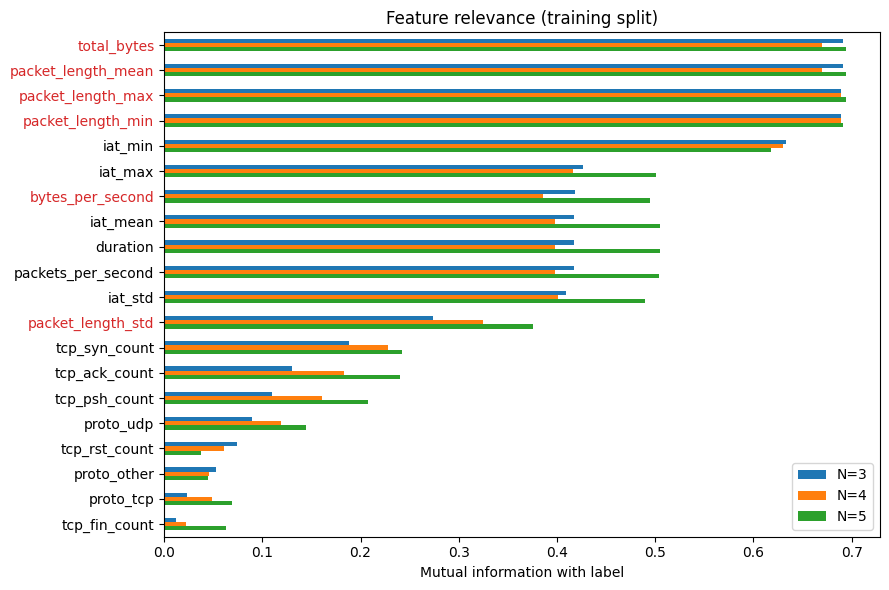

,N=3,N=4,N=5
total_bytes,0.691,0.670,0.694
packet_length_mean,0.691,0.669,0.694
packet_length_max,0.689,0.689,0.694
packet_length_min,0.689,0.689,0.691
iat_min,0.633,0.630,0.617
iat_max,0.427,0.416,0.501
bytes_per_second,0.419,0.386,0.494
iat_mean,0.417,0.398,0.504
duration,0.417,0.398,0.504
packets_per_second,0.417,0.398,0.504


In [18]:
MI_SAMPLE = 50_000
all_feats = USABLE_FEATURES
discrete_mask = [f in FLAG_FEATURES or f in PROTO_FEATURES for f in all_feats]

mi = {}
for n in N_VALUES:
    train_df = splits[n][0].sample(n=min(MI_SAMPLE, len(splits[n][0])), random_state=RANDOM_STATE)
    mi[n] = mutual_info_classif(
        train_df[all_feats], train_df["y"], discrete_features=discrete_mask, random_state=RANDOM_STATE,
    )
mi_df = pd.DataFrame(mi, index=all_feats).rename(columns=lambda n: f"N={n}")
mi_df = mi_df.sort_values(f"N={N_VALUES[0]}", ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
mi_df.plot.barh(ax=ax)
ax.invert_yaxis()
ax.set_xlabel("Mutual information with label")
ax.set_title("Feature relevance (training split)")
for label in ax.get_yticklabels():
    if label.get_text() in SIZE_FEATURES:
        label.set_color("tab:red")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "mutual_information.png", dpi=150)
plt.show()
mi_df.round(3)

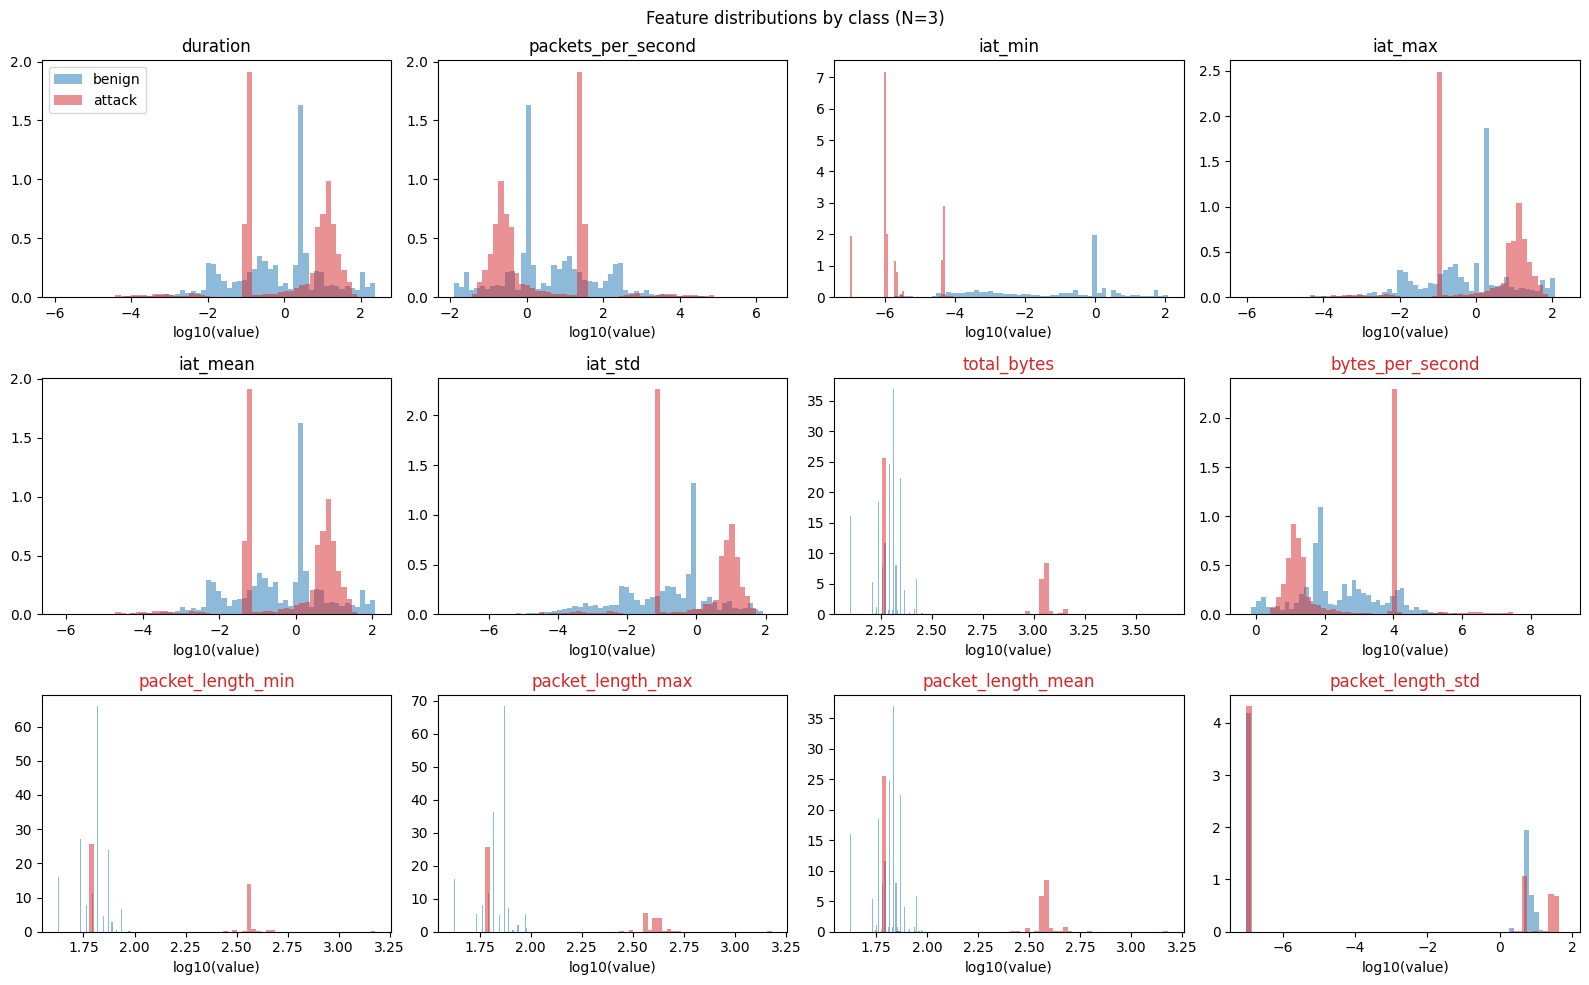

In [19]:
# Per-class distributions for the first N (log scale). Size features are capped at 96 bytes for benign.
n = N_VALUES[0]
plot_df = splits[n][0].sample(n=20_000, random_state=RANDOM_STATE)
plot_feats = [f for f in TIMING_FEATURES + SIZE_FEATURES if f in USABLE_FEATURES]

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, feat in zip(axes.flat, plot_feats):
    vals = np.log10(plot_df[feat].clip(lower=1e-7))
    for y, name, color in [(0, "benign", "tab:blue"), (1, "attack", "tab:red")]:
        ax.hist(vals[plot_df["y"] == y], bins=60, alpha=0.5, density=True, label=name, color=color)
    ax.set_title(feat, color="tab:red" if feat in SIZE_FEATURES else "black")
    ax.set_xlabel("log10(value)")
for ax in axes.flat[len(plot_feats):]:
    ax.set_visible(False)
axes.flat[0].legend()
fig.suptitle(f"Feature distributions by class (N={n})")
plt.tight_layout()
plt.savefig(RESULTS_DIR / f"feature_distributions_n{n}.png", dpi=150)
plt.show()

### Selected features for training

Set `SELECTED_FEATURES` from the analysis above. These are the **only** features used for training and
testing (Section 7), evaluation (Section 8) and the saved models (Section 9). Re-run from this cell after
changing it; Sections 1-6 do not need to be re-run.

In [38]:
# Note: total_bytes and packet_length_max are size features, so they are affected by the 96-byte MAWI
# snaplen cap (benign values never exceed 96 bytes per packet).
SELECTED_FEATURES = ["total_bytes", "packet_length_max", "iat_max"]

FEATURE_SETS = {"selected": SELECTED_FEATURES}

for name, feats in FEATURE_SETS.items():
    not_usable = set(feats) - set(USABLE_FEATURES)
    assert not not_usable, f"{name!r}: not usable candidate features (typo, identifier or constant): {not_usable}"
    assert len(feats) == len(set(feats)), f"{name!r}: duplicate features"

print(f"Features used for training and testing ({len(SELECTED_FEATURES)}): {SELECTED_FEATURES}")
mi_df.loc[SELECTED_FEATURES].round(3)

Features used for training and testing (3): ['total_bytes', 'packet_length_max', 'iat_max']


,N=3,N=4,N=5
total_bytes,0.691,0.670,0.694
packet_length_max,0.689,0.689,0.694
iat_max,0.427,0.416,0.501


### Sample distribution in the selected-feature space

Scatter plots of a random sample of the **training split** (attack and benign, equal counts) for each N:
one 2D plot per pair of selected features, and one 3D plot of the first three selected features.
Axes are `log10(value)` because the features span several orders of magnitude (values are clipped at
`1e-7` so zeros, e.g. `iat_min = 0`, stay visible at the bottom of the axis). Set `SCATTER_LOG = False`
for raw values.

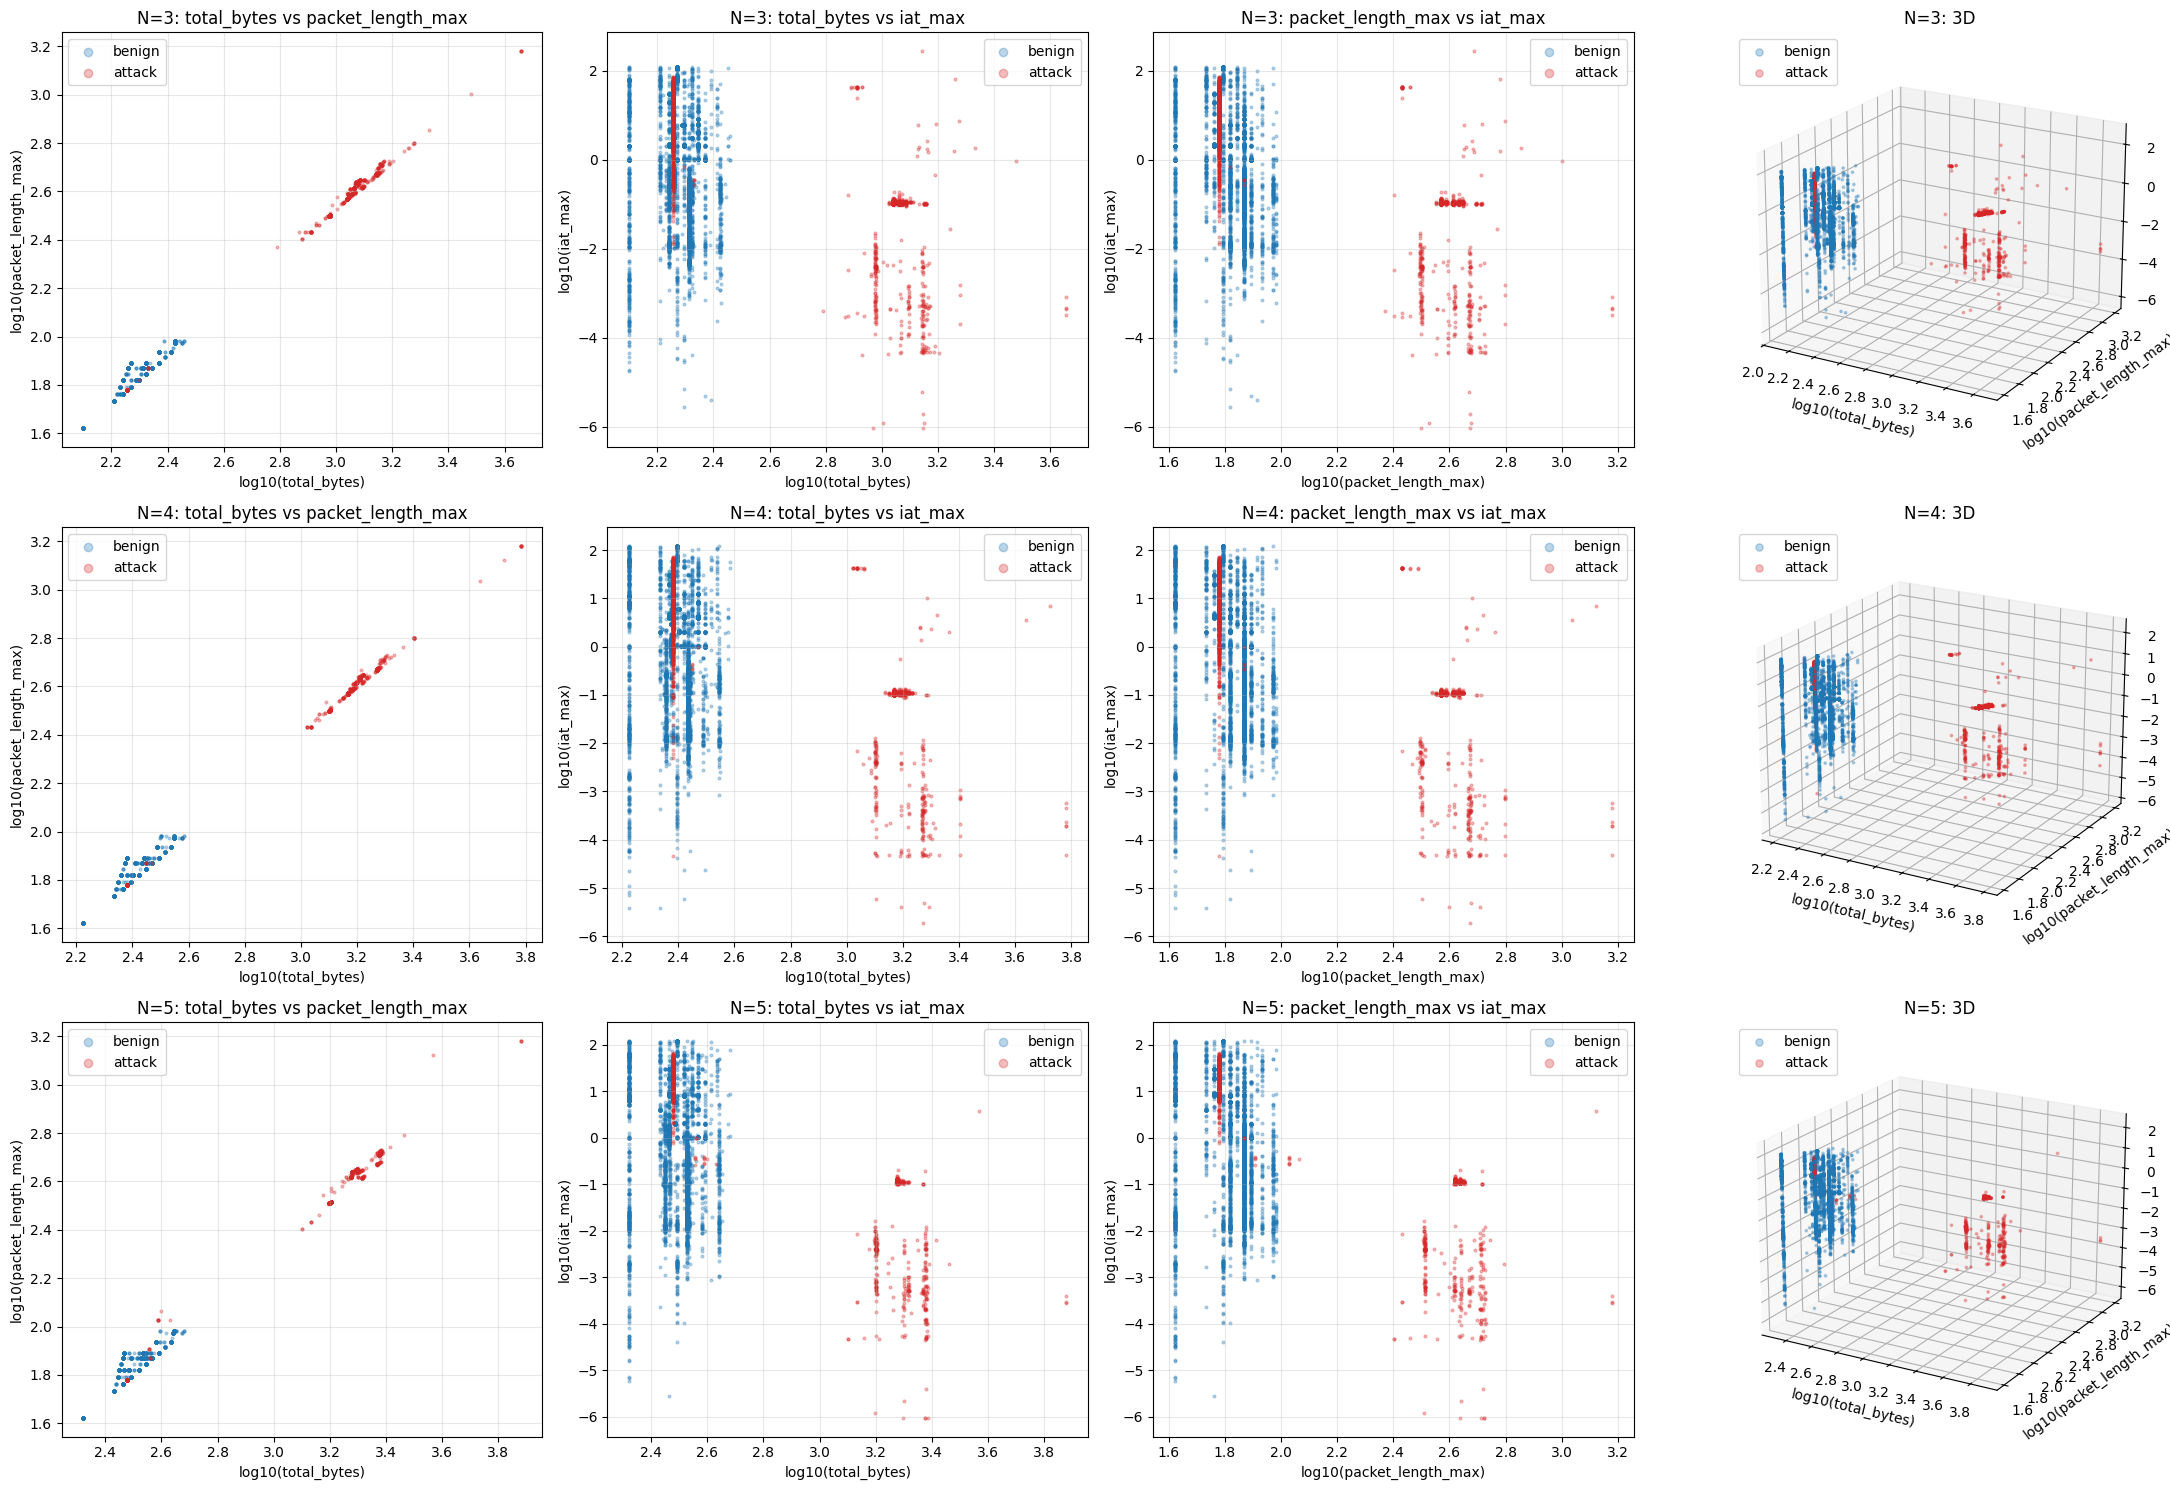

In [39]:
from itertools import combinations

from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3d projection)

SCATTER_SAMPLES_PER_CLASS = 5_000
SCATTER_LOG = True

assert len(SELECTED_FEATURES) >= 2, "Need at least 2 selected features to plot"
pairs = list(combinations(SELECTED_FEATURES, 2))
feats_3d = SELECTED_FEATURES[:3]
n_cols = len(pairs) + (1 if len(feats_3d) == 3 else 0)
CLASS_STYLE = [(0, "benign", "tab:blue"), (1, "attack", "tab:red")]


def axis_values(df, feat):
    return np.log10(df[feat].clip(lower=1e-7)) if SCATTER_LOG else df[feat]


def axis_label(feat):
    return f"log10({feat})" if SCATTER_LOG else feat


fig = plt.figure(figsize=(5.5 * n_cols, 5 * len(N_VALUES)))
for row, n in enumerate(N_VALUES):
    train_df = splits[n][0]
    sample = pd.concat([
        train_df[train_df["y"] == y].sample(
            n=min(SCATTER_SAMPLES_PER_CLASS, int((train_df["y"] == y).sum())), random_state=RANDOM_STATE)
        for y, _, _ in CLASS_STYLE
    ])

    for col, (fx, fy) in enumerate(pairs):
        ax = fig.add_subplot(len(N_VALUES), n_cols, row * n_cols + col + 1)
        for y, name, color in CLASS_STYLE:
            s = sample[sample["y"] == y]
            ax.scatter(axis_values(s, fx), axis_values(s, fy), s=4, alpha=0.3, color=color, label=name)
        ax.set_xlabel(axis_label(fx))
        ax.set_ylabel(axis_label(fy))
        ax.set_title(f"N={n}: {fx} vs {fy}")
        ax.grid(alpha=0.3)
        ax.legend(markerscale=3, loc="best")

    if len(feats_3d) == 3:
        fx, fy, fz = feats_3d
        ax = fig.add_subplot(len(N_VALUES), n_cols, row * n_cols + n_cols, projection="3d")
        for y, name, color in CLASS_STYLE:
            s = sample[sample["y"] == y]
            ax.scatter(axis_values(s, fx), axis_values(s, fy), axis_values(s, fz),
                       s=3, alpha=0.3, color=color, label=name)
        ax.set_xlabel(axis_label(fx))
        ax.set_ylabel(axis_label(fy))
        ax.set_zlabel(axis_label(fz))
        ax.set_title(f"N={n}: 3D")
        ax.view_init(elev=20, azim=-60)
        ax.legend(markerscale=3, loc="upper left")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "selected_features_scatter.png", dpi=150)
plt.show()

### Descriptive statistics of the selected features (raw and scaled)

For each N, statistics of every selected feature on the train and test splits, per class and overall:

* **raw**: the values as extracted from the PCAPs.
* **scaled**: after the same preprocessing as Section 7, a `StandardScaler` fit on the **training split only**
  and applied to both splits. Scaled training data has mean 0 and std 1 by construction; the test split
  is close to that, but not exactly.

All statistics are saved to `results/selected_features_stats.csv`.

In [40]:
STAT_PERCENTILES = [0.01, 0.25, 0.50, 0.75, 0.99]


def describe(values):
    q = values.quantile(STAT_PERCENTILES)
    return {
        "count": len(values),
        "min": values.min(),
        **{f"p{int(p * 100)}": q[p] for p in STAT_PERCENTILES},
        "max": values.max(),
        "mean": values.mean(),
        "std": values.std(),
        "n_unique": values.nunique(),
        "zero_pct": 100 * (values == 0).mean(),
    }


stats_rows = []
for n in N_VALUES:
    train_df, test_df = splits[n]
    scaler = StandardScaler().fit(train_df[SELECTED_FEATURES])  # same as Section 7: fit on train only
    for split_name, df in [("train", train_df), ("test", test_df)]:
        versions = {
            "raw": df[SELECTED_FEATURES],
            "scaled": pd.DataFrame(scaler.transform(df[SELECTED_FEATURES]),
                                   columns=SELECTED_FEATURES, index=df.index),
        }
        for version, values in versions.items():
            for cls_name, mask in [("all", slice(None)), ("benign", df["y"] == 0), ("attack", df["y"] == 1)]:
                for feat in SELECTED_FEATURES:
                    stats_rows.append({
                        "N": n, "split": split_name, "version": version, "class": cls_name,
                        "feature": feat, **describe(values.loc[mask, feat]),
                    })

    print(f"N={n}: scaler fit on train  mean_ ={ {f: round(float(v), 6) for f, v in zip(SELECTED_FEATURES, scaler.mean_)} }")
    print(f"     {'':18}scale_={ {f: round(float(v), 6) for f, v in zip(SELECTED_FEATURES, scaler.scale_)} }")

stats_df = pd.DataFrame(stats_rows)
stats_df.to_csv(RESULTS_DIR / "selected_features_stats.csv", index=False)
print("Saved:", RESULTS_DIR / "selected_features_stats.csv")

STAT_COLUMNS = ["count", "min", "p1", "p25", "p50", "p75", "p99", "max", "mean", "std", "n_unique", "zero_pct"]
with pd.option_context("display.float_format", "{:.6g}".format):
    for n in N_VALUES:
        for version in ["raw", "scaled"]:
            table = stats_df[(stats_df.N == n) & (stats_df.split == "train") & (stats_df.version == version)]
            print(f"\n===== N={n}  {version.upper()}  (training split)")
            display(table.set_index(["feature", "class"])[STAT_COLUMNS])

N=3: scaler fit on train  mean_ ={'total_bytes': 383.721417, 'packet_length_max': 133.227409, 'iat_max': 8.693457}
                       scale_={'total_bytes': 401.5946, 'packet_length_max': 140.944015, 'iat_max': 17.922485}
N=4: scaler fit on train  mean_ ={'total_bytes': 570.865927, 'packet_length_max': 148.243181, 'iat_max': 8.079232}
                       scale_={'total_bytes': 577.150532, 'packet_length_max': 149.839875, 'iat_max': 16.897732}
N=5: scaler fit on train  mean_ ={'total_bytes': 757.600836, 'packet_length_max': 167.758937, 'iat_max': 8.287857}
                       scale_={'total_bytes': 726.298454, 'packet_length_max': 166.448145, 'iat_max': 15.705397}
Saved: /home/ubuntu/DDoS_ML/offline/results/selected_features_stats.csv

===== N=3  RAW  (training split)


,,count,min,p1,p25,p50,p75,p99,max,mean,std,n_unique,zero_pct
feature,class,,,,,,,,,,,,
total_bytes,all,700000,102,126,180,198,222,1395,4542,383.721,401.595,699,0
packet_length_max,all,700000,34,42,60,66,74,469,1514,133.227,140.944,465,0
iat_max,all,700000,0,0.000235078,0.107725,2.00006,11.0075,108.963,771.894,8.69346,17.9225,483275,0.000285714
total_bytes,benign,350000,102,126,182,198,210,266,288,194.965,30.971,47,0
packet_length_max,benign,350000,34,42,66,74,74,94,96,67.9229,11.3774,15,0
iat_max,benign,350000,9.53674e-07,0.000329018,0.104827,1.01573,2.04899,119.758,120.428,8.14897,22.0882,249489,0
total_bytes,attack,350000,180,180,180,180,1101,1433,4542,572.477,500.34,658,0
packet_length_max,attack,350000,60,60,60,60,373,492,1514,198.532,176.272,454,0
iat_max,attack,350000,0,0.000185013,0.107802,6.47426,14.0051,51.6517,771.894,9.23794,12.4078,245576,0.000571429



===== N=3  SCALED  (training split)


,,count,min,p1,p25,p50,p75,p99,max,mean,std,n_unique,zero_pct
feature,class,,,,,,,,,,,,
total_bytes,all,700000,-0.701507,-0.641745,-0.507281,-0.46246,-0.402698,2.51816,10.3544,-1.56522e-17,1,699,0
packet_length_max,all,700000,-0.70402,-0.64726,-0.51955,-0.47698,-0.420219,2.38231,9.7966,-6.7197e-17,1,465,0
iat_max,all,700000,-0.485059,-0.485046,-0.479048,-0.373464,0.129114,5.59464,42.5834,-2.61277e-17,1,483274,0
total_bytes,benign,350000,-0.701507,-0.641745,-0.502301,-0.46246,-0.432579,-0.293135,-0.238353,-0.470016,0.07712,47,0
packet_length_max,benign,350000,-0.70402,-0.64726,-0.47698,-0.420219,-0.420219,-0.278319,-0.264129,-0.463337,0.0807228,15,0
iat_max,benign,350000,-0.485059,-0.48504,-0.47921,-0.428385,-0.370734,6.19696,6.2343,-0.0303801,1.23243,249489,0
total_bytes,attack,350000,-0.507281,-0.507281,-0.507281,-0.507281,1.78608,2.61278,10.3544,0.470016,1.24588,658,0
packet_length_max,attack,350000,-0.51955,-0.51955,-0.51955,-0.51955,1.70119,2.5455,9.7966,0.463337,1.25065,454,0
iat_max,attack,350000,-0.485059,-0.485048,-0.479044,-0.123822,0.296369,2.39689,42.5834,0.0303801,0.692302,245576,0



===== N=4  RAW  (training split)


...

,,count,min,p1,p25,p50,p75,p99,max,mean,std,n_unique,zero_pct
feature,class,,,,,,,,,,,,
total_bytes,all,700000,-0.753471,-0.698026,-0.573275,-0.531691,-0.379218,2.23362,9.50382,4.82357e-17,1,694,0
packet_length_max,all,700000,-0.762435,-0.709045,-0.588917,-0.522179,-0.362008,2.12732,9.11478,-5.63156e-17,1,458,0
iat_max,all,700000,-0.478125,-0.478113,-0.471823,-0.418662,0.067797,5.2525,72.9378,-4.14196e-17,1,464068,0
total_bytes,benign,350000,-0.753471,-0.698026,-0.587136,-0.531691,-0.51783,-0.379218,-0.323773,-0.545064,0.073492,58,0
packet_length_max,benign,350000,-0.762435,-0.709045,-0.548874,-0.495483,-0.495483,-0.362008,-0.34866,-0.536532,0.0794901,15,0
iat_max,benign,350000,-0.478125,-0.478112,-0.473888,-0.418511,-0.23194,6.42906,6.64756,0.011014,1.22151,262638,0
total_bytes,attack,350000,-0.573275,-0.573275,-0.573275,-0.573275,1.72422,2.32025,9.50382,0.545064,1.18339,646,0
packet_length_max,attack,350000,-0.588917,-0.588917,-0.588917,-0.588917,1.75358,2.20073,9.11478,0.536532,1.19078,447,0
iat_max,attack,350000,-0.478125,-0.478116,-0.471798,-0.424245,0.28179,2.48088,72.9378,-0.011014,0.712511,212816,0



===== N=5  RAW  (training split)


,,count,min,p1,p25,p50,p75,p99,max,mean,std,n_unique,zero_pct
feature,class,,,,,,,,,,,,
total_bytes,all,700000,170,210,300,338,1905,2090,7570,757.601,726.299,447,0
packet_length_max,all,700000,34,42,60,74,435,450,1514,167.759,166.448,236,0
iat_max,all,700000,9.53674e-07,0.000319958,0.10984,0.328189,11.396,81.6286,481.705,8.28786,15.7054,425846,0
total_bytes,benign,350000,170,210,290,330,338,438,480,316.305,53.3769,71,0
packet_length_max,benign,350000,34,42,66,74,74,94,96,67.7029,12.2155,15,0
iat_max,benign,350000,9.53674e-07,0.000509024,0.0604041,0.89376,8.19196,110.441,120.408,8.32015,19.2913,258944,0
total_bytes,attack,350000,300,300,300,1905,1905,2385,7570,1198.9,814.056,385,0
packet_length_max,attack,350000,60,60,60,435,435,515,1514,267.815,187.719,223,0
iat_max,attack,350000,9.53674e-07,0.000244141,0.109932,0.110624,15.1531,44.5135,481.705,8.25557,11.0075,175610,0



===== N=5  SCALED  (training split)


,,count,min,p1,p25,p50,p75,p99,max,mean,std,n_unique,zero_pct
feature,class,,,,,,,,,,,,
total_bytes,all,700000,-0.809035,-0.753961,-0.630045,-0.577725,1.57979,1.83451,9.37961,3.97904e-18,1,447,0
packet_length_max,all,700000,-0.803607,-0.755544,-0.647402,-0.563292,1.60555,1.69567,8.08805,3.96889e-17,1,236,0
iat_max,all,700000,-0.527708,-0.527687,-0.520714,-0.506811,0.197905,4.66978,30.1436,2.81273e-17,1,425846,0
total_bytes,benign,350000,-0.809035,-0.753961,-0.643814,-0.58874,-0.577725,-0.440041,-0.382213,-0.607596,0.0734917,71,0
packet_length_max,benign,350000,-0.803607,-0.755544,-0.611355,-0.563292,-0.563292,-0.443135,-0.431119,-0.601124,0.0733891,15,0
iat_max,benign,350000,-0.527708,-0.527675,-0.523862,-0.4708,-0.00610571,6.50436,7.13895,0.00205601,1.22832,258944,0
total_bytes,attack,350000,-0.630045,-0.630045,-0.630045,1.57979,1.57979,2.24068,9.37961,0.607596,1.12083,385,0
packet_length_max,attack,350000,-0.647402,-0.647402,-0.647402,1.60555,1.60555,2.08618,8.08805,0.601124,1.12779,223,0
iat_max,attack,350000,-0.527708,-0.527692,-0.520708,-0.520664,0.437125,2.30658,30.1436,-0.00205601,0.700871,175610,0


In [41]:
# Test-split statistics side by side with train, to check the test data looks like the training data.
with pd.option_context("display.float_format", "{:.6g}".format):
    for version in ["raw", "scaled"]:
        cmp = stats_df[(stats_df["class"] == "all") & (stats_df.version == version)].pivot_table(
            index=["N", "feature"], columns="split", values=["min", "p50", "max", "mean", "std"])
        print(f"\n===== {version.upper()}: train vs test (all classes)")
        display(cmp)


===== RAW: train vs test (all classes)


max            mean                 min                  p50              std        
split                  test   train    test   train        test       train     test    train    test   train
N feature                                                                                                    
3 iat_max           1229.62 771.894 8.65441 8.69346 9.53674e-07           0  2.00006  2.00006 17.9391 17.9225
  packet_length_max    1514    1514 133.267 133.227          34          34       66       66 141.156 140.944
  total_bytes          4542    4542 383.817 383.721         102         102      198      198 402.188 401.595
4 iat_max           808.888 1240.56 8.02973 8.07923 9.53674e-07 9.53674e-07  1.00589   1.0048 16.6474 16.8977
  packet_length_max    1514    1514 148.212 148.243          34          34       70       70 149.723  149.84
  total_bytes          6056    6056 570.773 570.866         136         136      264      264 576.808 577.151
5 iat_max           120.369 481.705  8.2582 8.28786 9.53674e-07 9.53674e-07 0.327029 0.328189 15.6352 15.7054
  packet_length_max    1514    1514 167.785 167.759          34          34       74       74  166.37 166.448
  total_bytes          7570    7570  757.68 757.601         170         170      338      338 725.905 726.299


===== SCALED: train vs test (all classes)


max                 mean                    min                 p50                std      
split                  test   train         test        train      test     train      test     train     test train
N feature                                                                                                           
3 iat_max           68.1224 42.5834  -0.00217877 -2.61277e-17 -0.485059 -0.485059 -0.373463 -0.373464  1.00093     1
  packet_length_max  9.7966  9.7966  0.000278726  -6.7197e-17  -0.70402  -0.70402  -0.47698  -0.47698   1.0015     1
  total_bytes       10.3544 10.3544   0.00023771 -1.56522e-17 -0.701507 -0.701507  -0.46246  -0.46246  1.00148     1
4 iat_max           47.3915 72.9378  -0.00292928 -4.14196e-17 -0.478125 -0.478125 -0.418597 -0.418662 0.985188     1
  packet_length_max 9.11478 9.11478 -0.000207297 -5.63156e-17 -0.762435 -0.762435 -0.522179 -0.522179 0.999219     1
  total_bytes       9.50382 9.50382   -0.0001606  4.82357e-17 -0.753471 -0.753471 -0.531691 -0.531691 0.999406     1
5 iat_max           7.13647 30.1436  -0.00188808  2.81273e-17 -0.527708 -0.527708 -0.506885 -0.506811 0.995529     1
  packet_length_max 8.08805 8.08805  0.000156743  3.96889e-17 -0.803607 -0.803607 -0.563292 -0.563292 0.999532     1
  total_bytes       9.37961 9.37961  0.000108634  3.97904e-18 -0.809035 -0.809035 -0.577725 -0.577725 0.999459     1

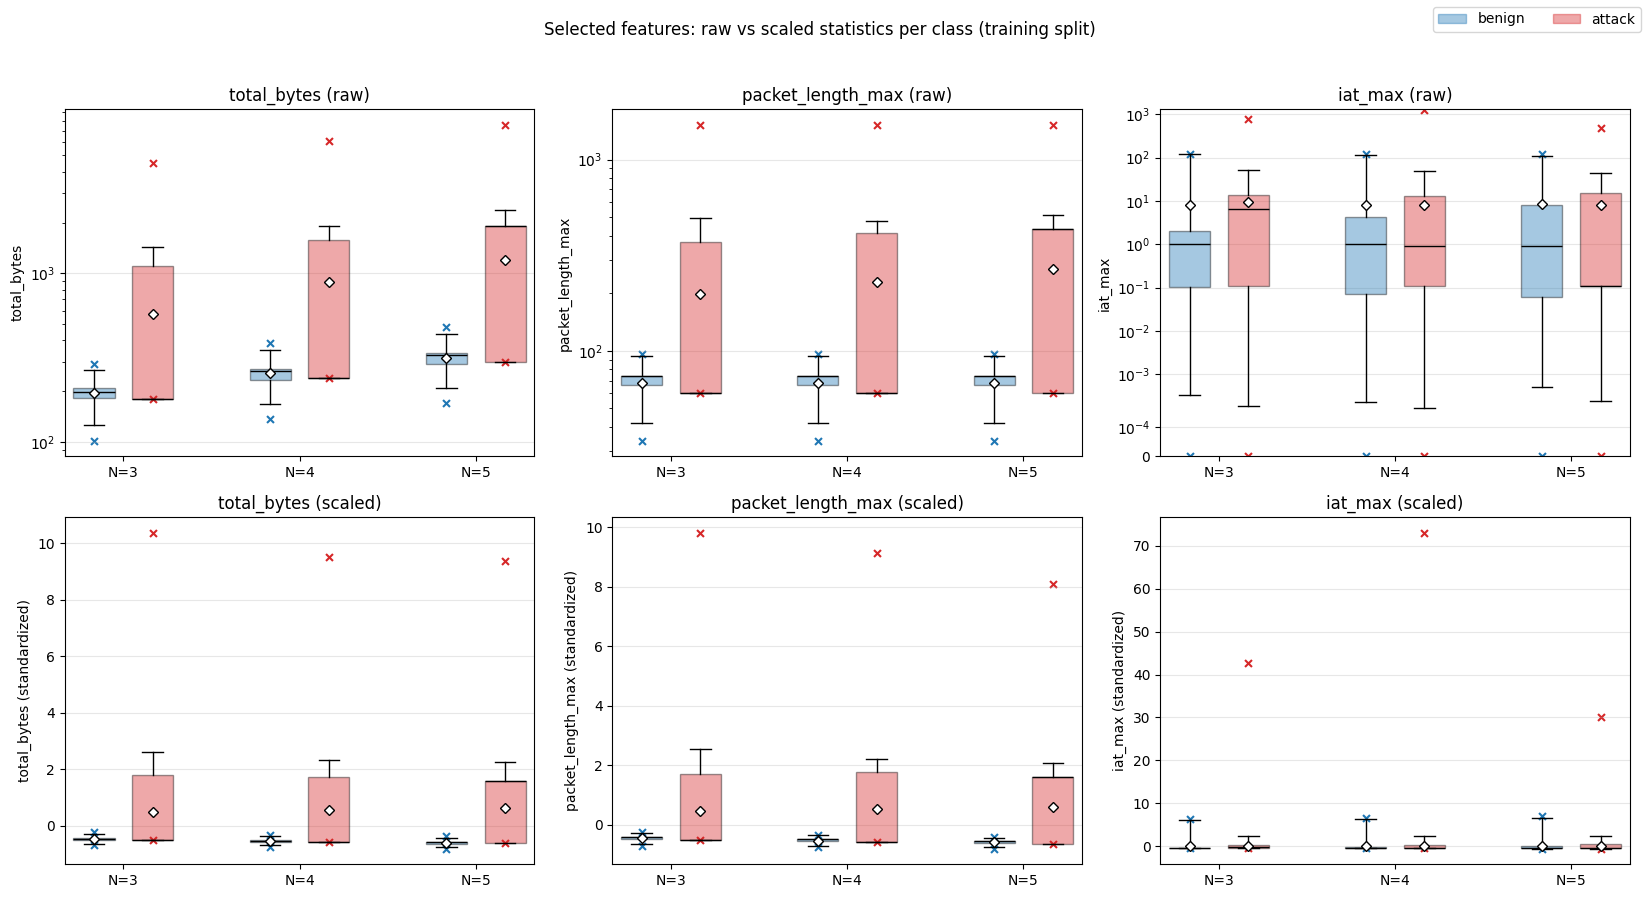

In [42]:
# Figure of the statistics above (training split), drawn directly from stats_df.
# Box = p25..p75, line = median, diamond = mean, whiskers = p1..p99, x = min / max.
# Raw values use a log y-axis; features that contain zeros (e.g. iat_min) use symlog starting at 0.
CLASS_COLORS = {"benign": "tab:blue", "attack": "tab:red"}
VERSIONS = ["raw", "scaled"]

fig, axes = plt.subplots(len(VERSIONS), len(SELECTED_FEATURES),
                         figsize=(5.5 * len(SELECTED_FEATURES), 4.5 * len(VERSIONS)), squeeze=False)
for row, version in enumerate(VERSIONS):
    for col, feat in enumerate(SELECTED_FEATURES):
        ax = axes[row, col]
        sub = stats_df[(stats_df.split == "train") & (stats_df.version == version) & (stats_df.feature == feat)]
        for j, n in enumerate(N_VALUES):
            for k, cls_name in enumerate(CLASS_COLORS):
                r = sub[(sub.N == n) & (sub["class"] == cls_name)].iloc[0]
                pos = j * 3 + k
                box = {"med": r.p50, "q1": r.p25, "q3": r.p75, "whislo": r.p1, "whishi": r.p99,
                       "mean": r["mean"], "fliers": [], "label": ""}
                ax.bxp([box], positions=[pos], widths=0.7, showmeans=True, patch_artist=True,
                       boxprops={"facecolor": CLASS_COLORS[cls_name], "alpha": 0.4},
                       medianprops={"color": "black"},
                       meanprops={"marker": "D", "markerfacecolor": "white",
                                  "markeredgecolor": "black", "markersize": 5})
                ax.scatter([pos, pos], [r["min"], r["max"]], marker="x", s=25, color=CLASS_COLORS[cls_name])
        ax.set_xticks([j * 3 + 0.5 for j in range(len(N_VALUES))])
        ax.set_xticklabels([f"N={n}" for n in N_VALUES])
        if version == "raw":
            if (sub["min"] > 0).all():
                ax.set_yscale("log")
            else:
                positive = sub[["p1", "p25", "p50", "p75", "p99", "max"]].to_numpy().ravel()
                positive = positive[positive > 0]
                ax.set_yscale("symlog", linthresh=positive.min() if len(positive) else 1e-6)
                ax.set_ylim(bottom=0)
        ax.set_title(f"{feat} ({version})")
        ax.set_ylabel(feat if version == "raw" else f"{feat} (standardized)")
        ax.grid(alpha=0.3, axis="y")

handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.4) for c in CLASS_COLORS.values()]
fig.legend(handles, list(CLASS_COLORS), loc="upper right", ncol=2)
fig.suptitle("Selected features: raw vs scaled statistics per class (training split)")
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.savefig(RESULTS_DIR / "selected_features_stats.png", dpi=150)
plt.show()

## 7. Train and test KNN

For each `(N, feature set)`, features are used as-is (`FEATURE_SCALING = "raw"`) or standardized with a
scaler fit on the training split only (`FEATURE_SCALING = "scaled"`), and the `max(K_VALUES)`
nearest training neighbors of every test point are computed **once**. Each `k` is then evaluated from the
first `k` neighbors: the attack score is the fraction of attack neighbors, and the prediction is the majority
vote. This gives the same predictions as `KNeighborsClassifier(n_neighbors=k)` (uniform weights, odd `k`)
without re-running the neighbor search for every `k`.

In [44]:
max_k = max(K_VALUES)
results = []
scores = {}  # (n, feature_set, k) -> attack-vote fraction on the test set, for ROC curves

for n in N_VALUES:
    train_df, test_df = splits[n]
    y_train = train_df["y"].to_numpy()
    y_test = test_df["y"].to_numpy()

    for fs_name, feats in FEATURE_SETS.items():
        if FEATURE_SCALING == "scaled":
            scaler = StandardScaler().fit(train_df[feats])  # fit on train only
            X_train = scaler.transform(train_df[feats])
            X_test = scaler.transform(test_df[feats])
        else:  # "raw": features as extracted, no preprocessing
            X_train = train_df[feats].to_numpy()
            X_test = test_df[feats].to_numpy()

        t0 = time.time()
        nn = NearestNeighbors(n_neighbors=max_k, n_jobs=-1).fit(X_train)
        fit_s = time.time() - t0
        t0 = time.time()
        _, idx = nn.kneighbors(X_test)
        query_s = time.time() - t0
        neighbor_labels = y_train[idx]

        for k in K_VALUES:
            score = neighbor_labels[:, :k].mean(axis=1)
            y_pred = (score > 0.5).astype(int)
            tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
            scores[(n, fs_name, k)] = score
            results.append({
                "N": n, "feature_set": fs_name, "scaling": FEATURE_SCALING, "n_features": len(feats), "k": k,
                "accuracy": accuracy_score(y_test, y_pred),
                "precision": precision_score(y_test, y_pred, zero_division=0),
                "recall": recall_score(y_test, y_pred, zero_division=0),
                "f1": f1_score(y_test, y_pred, zero_division=0),
                "roc_auc": roc_auc_score(y_test, score),
                "fpr": fp / (fp + tn), "fnr": fn / (fn + tp),
                "tp": tp, "fp": fp, "tn": tn, "fn": fn,
                "fit_s": fit_s, "query_s": query_s,
            })
        print(f"N={n} {fs_name:<8} {FEATURE_SCALING:<6} fit={fit_s:5.1f}s  query({len(X_test):,} x k={max_k})={query_s:6.1f}s")

results_df = pd.DataFrame(results)
results_csv = RESULTS_DIR / f"knn_binary_results_{FEATURE_SCALING}.csv"
results_df.to_csv(results_csv, index=False)
print("Saved:", results_csv)

N=3 selected raw    fit=  0.5s  query(300,000 x k=15)=   9.7s
N=4 selected raw    fit=  0.5s  query(300,000 x k=15)=  11.2s
N=5 selected raw    fit=  0.5s  query(300,000 x k=15)=   7.2s
Saved: /home/ubuntu/DDoS_ML/offline/results/knn_binary_results_raw.csv


## 8. Compare the evaluation

In [45]:
# Best k per (N, feature set), ranked by F1.
best = (
    results_df.sort_values("f1", ascending=False)
    .groupby(["N", "feature_set"], as_index=False).first()
    .sort_values(["feature_set", "N"])
)
best[["N", "feature_set", "k", "accuracy", "precision", "recall", "f1", "roc_auc", "fpr", "fnr"]].round(4)

,N,feature_set,k,accuracy,precision,recall,f1,roc_auc,fpr,fnr
0,3,selected,7,0.9998,0.9998,0.9997,0.9998,0.9999,0.0002,0.0003
1,4,selected,7,0.9998,0.9998,0.9998,0.9998,0.9999,0.0002,0.0002
2,5,selected,1,0.9999,0.9999,0.9999,0.9999,0.9999,0.0001,0.0001


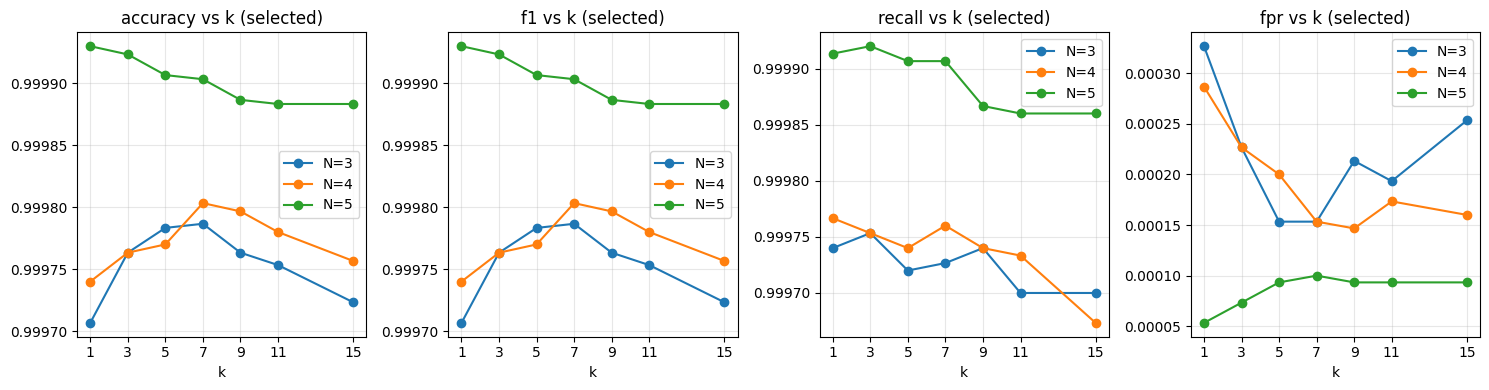

In [46]:
metrics = ["accuracy", "f1", "recall", "fpr"]
fig, axes = plt.subplots(len(FEATURE_SETS), len(metrics), figsize=(15, 4 * len(FEATURE_SETS)), squeeze=False)
for row, fs_name in enumerate(FEATURE_SETS):
    for col, metric in enumerate(metrics):
        ax = axes[row, col]
        sub = results_df[results_df.feature_set == fs_name]
        for n in N_VALUES:
            s = sub[sub.N == n]
            ax.plot(s["k"], s[metric], marker="o", label=f"N={n}")
        ax.set_title(f"{metric} vs k ({fs_name})")
        ax.set_xlabel("k")
        ax.set_xticks(K_VALUES)
        ax.grid(alpha=0.3)
        ax.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "metrics_vs_k.png", dpi=150)
plt.show()

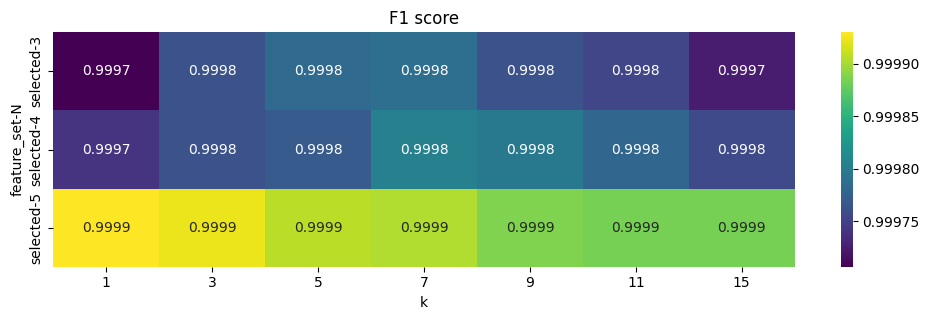

In [47]:
# Heatmap of F1 for every (N, feature set) x k.
pivot = results_df.pivot_table(index=["feature_set", "N"], columns="k", values="f1")
fig, ax = plt.subplots(figsize=(10, 0.6 * len(pivot) + 1.5))
sns.heatmap(pivot, annot=True, fmt=".4f", cmap="viridis", ax=ax)
ax.set_title("F1 score")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "f1_heatmap.png", dpi=150)
plt.show()

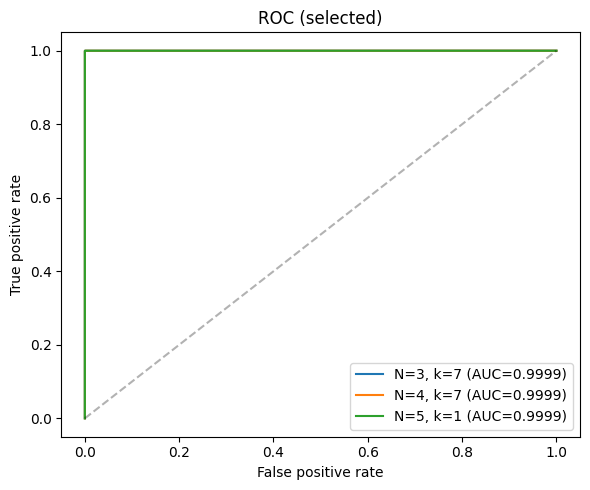

In [48]:
# ROC curves at the best k for each (N, feature set).
fig, axes = plt.subplots(1, len(FEATURE_SETS), figsize=(6 * len(FEATURE_SETS), 5), squeeze=False)
for ax, fs_name in zip(axes[0], FEATURE_SETS):
    for n in N_VALUES:
        k = int(best[(best.N == n) & (best.feature_set == fs_name)]["k"].iloc[0])
        y_test = splits[n][1]["y"].to_numpy()
        fpr, tpr, _ = roc_curve(y_test, scores[(n, fs_name, k)])
        auc = roc_auc_score(y_test, scores[(n, fs_name, k)])
        ax.plot(fpr, tpr, label=f"N={n}, k={k} (AUC={auc:.4f})")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.3)
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_title(f"ROC ({fs_name})")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "roc_curves.png", dpi=150)
plt.show()

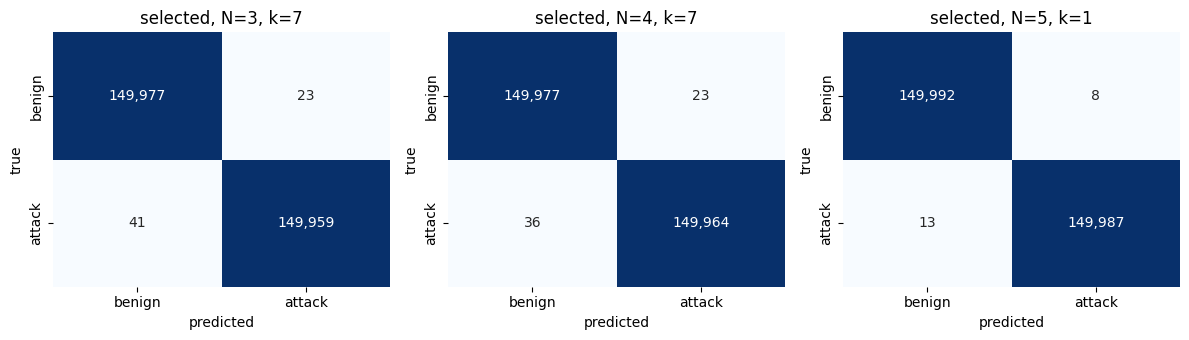

In [49]:
# Confusion matrices at the best k for each (N, feature set).
fig, axes = plt.subplots(len(FEATURE_SETS), len(N_VALUES),
                         figsize=(4 * len(N_VALUES), 3.5 * len(FEATURE_SETS)), squeeze=False)
for row, fs_name in enumerate(FEATURE_SETS):
    for col, n in enumerate(N_VALUES):
        r = best[(best.N == n) & (best.feature_set == fs_name)].iloc[0]
        cm = np.array([[r.tn, r.fp], [r.fn, r.tp]])
        sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[row, col],
                    xticklabels=["benign", "attack"], yticklabels=["benign", "attack"])
        axes[row, col].set_title(f"{fs_name}, N={n}, k={int(r.k)}")
        axes[row, col].set_xlabel("predicted")
        axes[row, col].set_ylabel("true")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrices.png", dpi=150)
plt.show()

In [50]:
# Detection rate per attack type (recall on each CICDDoS2019 class) at the best k.
rows = []
for _, r in best.iterrows():
    n, fs_name, k = int(r.N), r.feature_set, int(r.k)
    test_df = splits[n][1]
    pred = scores[(n, fs_name, k)] > 0.5
    for attack_type, grp in test_df.groupby("attack_type"):
        hit = pred[grp.index].mean() if attack_type != "Benign" else 1 - pred[grp.index].mean()
        rows.append({"feature_set": fs_name, "N": n, "attack_type": attack_type,
                     "test_rows": len(grp), "correct_rate": hit})
per_type = pd.DataFrame(rows)
per_type.to_csv(RESULTS_DIR / "knn_binary_per_attack_type.csv", index=False)
per_type.pivot_table(index="attack_type", columns=["feature_set", "N"], values="correct_rate").round(4)

feature_set selected                
N                  3       4       5
attack_type                         
Benign        0.9998  0.9998  0.9999
LDAP          0.9724  0.9744  1.0000
MSSQL         0.9963  0.9945  0.9697
NetBIOS       0.9968  1.0000  1.0000
Portmap       0.9143  1.0000  0.8571
Syn           0.9997  0.9997  0.9998
UDP           1.0000  1.0000  1.0000
UDPLag        0.9333  0.9375  1.0000

## 9. Save the best model per (N, feature set)

Each saved model is a `scaler → KNeighborsClassifier` pipeline trained on the full training split, with the
feature list stored alongside it. The scaler step is a `StandardScaler` when `FEATURE_SCALING = "scaled"`
and `"passthrough"` (no preprocessing) when `FEATURE_SCALING = "raw"`, so the saved model always expects
raw feature values as input.

In [51]:
for _, r in best.iterrows():
    n, fs_name, k = int(r.N), r.feature_set, int(r.k)
    feats = FEATURE_SETS[fs_name]
    train_df = splits[n][0]
    model = Pipeline([
        ("scaler", StandardScaler() if FEATURE_SCALING == "scaled" else "passthrough"),
        ("knn", KNeighborsClassifier(n_neighbors=k, n_jobs=-1)),
    ]).fit(train_df[feats], train_df["y"])
    out = MODELS_DIR / f"knn_binary_{fs_name}_{FEATURE_SCALING}_n{n}_k{k}.joblib"
    joblib.dump({"model": model, "features": feats, "scaling": FEATURE_SCALING, "N": n, "k": k,
                 "metrics": r.to_dict()}, out)
    print("Saved:", out)

Saved: /home/ubuntu/DDoS_ML/offline/models/knn_binary_selected_raw_n3_k7.joblib
Saved: /home/ubuntu/DDoS_ML/offline/models/knn_binary_selected_raw_n4_k7.joblib
Saved: /home/ubuntu/DDoS_ML/offline/models/knn_binary_selected_raw_n5_k1.joblib
